<a href="https://colab.research.google.com/github/varshithadagumati-bit/ADS/blob/main/project_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# SMART DISEASE PREDICTION SYSTEM
# COMPLETE ML PROJECT
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

print("Libraries imported successfully! ✅")

Libraries imported successfully! ✅


In [ ]:
#UPLOAD CSV DATASET
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully! ✅")
print("File Name:", filename)

Saving Smart_Disease_Raw_Final.csv to Smart_Disease_Raw_Final.csv
Dataset loaded successfully! ✅
File Name: Smart_Disease_Raw_Final.csv


In [ ]:
#VIEW RAW DATASET
print("First 5 Records:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

First 5 Records:


,Disease,Age,BMI,Severity_Score,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,...,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Bronchial Asthma,39.0,23.9,2,fatigue,cough,high_fever,family_history,mucoid_sputum,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Impetigo,75.0,20.7,2,skin_rash,high_fever,blister,red_sore_around_nose,yellow_crust_ooze,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Hypertension,49.0,19.9,7,headache,chest_pain,dizziness,loss_of_balance,lack_of_concentration,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Hepatitis E,57.0,26.2,8,joint_pain,vomiting,fatigue,high_fever,yellowish_skin,dark_urine,...,loss_of_appetite,abdominal_pain,yellowing_of_eyes,acute_liver_failure,coma,stomach_bleeding,NaN,NaN,NaN,NaN
4,Pneumonia,41.0,30.0,10,chills,fatigue,cough,high_fever,breathlessness,malaise,...,chest_pain,fast_heart_rate,rusty_sputum,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset Shape:
(4975, 21)

Column Names:
['Disease', 'Age', 'BMI', 'Severity_Score', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']


In [ ]:
#DATASET INFORMATION
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4975 entries, 0 to 4974
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Disease         4975 non-null   object 
 1   Age             4950 non-null   float64
 2   BMI             4950 non-null   float64
 3   Severity_Score  4975 non-null   int64  
 4   Symptom_1       4973 non-null   object 
 5   Symptom_2       4973 non-null   object 
 6   Symptom_3       4973 non-null   object 
 7   Symptom_4       4622 non-null   object 
 8   Symptom_5       3724 non-null   object 
 9   Symptom_6       2963 non-null   object 
 10  Symptom_7       2294 non-null   object 
 11  Symptom_8       1971 non-null   object 
 12  Symptom_9       1710 non-null   object 
 13  Symptom_10      1526 non-null   object 
 14  Symptom_11      1205 non-null   object 
 15  Symptom_12      754 non-null    object 
 16  Symptom_13      512 non-null    object 
 17  Symptom_14  

In [ ]:
#CHECK DATASET SIZE
print("Number of Records:", df.shape[0])
print("Number of Attributes:", df.shape[1])

Number of Records: 4975
Number of Attributes: 21


In [ ]:
#CHECK DISEASE CLASSES
print("Number of Disease Classes:",
      df["Disease"].nunique())

print("\nDisease Classes:")

for i, disease in enumerate(df["Disease"].unique(), start=1):
    print(i, ":", disease)

Number of Disease Classes: 49

Disease Classes:
1 : Bronchial Asthma
2 : Impetigo
3 : Hypertension 
4 : Hepatitis E
5 : Pneumonia
6 : Hyperthyroidism
7 : Malaria
8 : Chicken pox
9 : Hepatitis B
10 : Osteoarthristis
11 : Paralysis (brain hemorrhage)
12 : Hepatitis D
13 : Fungal infection
14 : Common Cold
15 : Acne
16 : Tuberculosis
17 : Dimorphic hemmorhoids(piles)
18 : (vertigo) Paroymsal  Positional Vertigo
19 : Hypoglycemia
20 : AIDS
21 : Heart attack
22 : Hepatitis C
23 : Psoriasis
24 : Diabetes 
25 : Typhoid
26 : Migraine
27 : Arthritis
28 : hepatitis A
29 : Cervical spondylosis
30 : Gastroenteritis
31 : Allergy
32 : Jaundice
33 : Varicose veins
34 : GERD
35 : Chronic cholestasis
36 : Hypothyroidism
37 : Alcoholic hepatitis
38 : Urinary tract infection
39 : Dengue
40 : Drug Reaction
41 : Peptic ulcer diseae
42 :  JAUNDICE 
43 :  MALARIA 
44 :  OSTEOARTHRISTIS 
45 :  PSORIASIS 
46 :  HEPATITIS C 
47 :  IMPETIGO 
48 :  HYPERTENSION  
49 :  HEPATITIS A 


In [ ]:
#CHECK MISSING VALUES
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Missing Values in Each Column:
Disease              0
Age                 25
BMI                 25
Severity_Score       0
Symptom_1            2
Symptom_2            2
Symptom_3            2
Symptom_4          353
Symptom_5         1251
Symptom_6         2012
Symptom_7         2681
Symptom_8         3004
Symptom_9         3265
Symptom_10        3449
Symptom_11        3770
Symptom_12        4221
Symptom_13        4463
Symptom_14        4665
Symptom_15        4732
Symptom_16        4780
Symptom_17        4902
dtype: int64

Total Missing Values: 47604


In [ ]:
#MISSING VALUE PERCENTAGE
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("Missing Value Percentage:")
print(
    missing_percentage
    .sort_values(ascending=False)
)

Missing Value Percentage:
Symptom_17        98.532663
Symptom_16        96.080402
Symptom_15        95.115578
Symptom_14        93.768844
Symptom_13        89.708543
Symptom_12        84.844221
Symptom_11        75.778894
Symptom_10        69.326633
Symptom_9         65.628141
Symptom_8         60.381910
Symptom_7         53.889447
Symptom_6         40.442211
Symptom_5         25.145729
Symptom_4          7.095477
Age                0.502513
BMI                0.502513
Symptom_1          0.040201
Symptom_3          0.040201
Symptom_2          0.040201
Severity_Score     0.000000
Disease            0.000000
dtype: float64


In [ ]:
#IDENTIFY SYMPTOM COLUMNS
symptom_cols = [
    col for col in df.columns
    if re.match(r"Symptom_\d+$", col)
]

print("Symptom Columns:")
print(symptom_cols)

print("\nNumber of Symptom Attributes:",
      len(symptom_cols))

Symptom Columns:
['Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']

Number of Symptom Attributes: 17


In [ ]:
#IDENTIFY NUMERICAL COLUMNS
numeric_cols = [
    "Age",
    "BMI",
    "Severity_Score"
]

print("Numerical Columns:")
print(numeric_cols)

Numerical Columns:
['Age', 'BMI', 'Severity_Score']


In [ ]:
#DATA CLEANING
# Clean Disease column

df["Disease"] = (
    df["Disease"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Clean symptom columns

for col in symptom_cols:

    df[col] = (
        df[col]
        .fillna("unknown")
        .astype(str)
        .str.strip()
        .str.lower()
    )

print("Data cleaning completed! ✅")

Data cleaning completed! ✅


In [ ]:
#HANDLE DUPLICATES
print("Duplicate Rows Before Removal:",
      df.duplicated().sum())

Duplicate Rows Before Removal: 32


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate removal completed! ✅")

print("Dataset Shape After Duplicate Removal:",
      df.shape)

Duplicate removal completed! ✅
Dataset Shape After Duplicate Removal: (4943, 21)


In [ ]:
#HANDLE MISSING NUMERICAL VALUES
print("Missing Numerical Values:")

print(
    df[numeric_cols]
    .isnull()
    .sum()
)

Missing Numerical Values:
Age               25
BMI               25
Severity_Score     0
dtype: int64


In [ ]:
# REPLACE MISSING VALUES WITH MEDIAN

for col in numeric_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

print("Missing values replaced with median!")

print("\nMissing values after replacement:")
print(df[numeric_cols].isnull().sum())

Missing values replaced with median!

Missing values after replacement:
Age               0
BMI               0
Severity_Score    0
dtype: int64


In [ ]:
#FEATURE ENGINEERING
# ==========================================
# FEATURE ENGINEERING
# ==========================================

df["Symptom_Count"] = (
    df[symptom_cols] != "unknown"
).sum(axis=1)

print("Symptom_Count created successfully! ✅")

display(
    df[
        ["Disease", "Symptom_Count"]
    ].head(10)
)

Symptom_Count created successfully! ✅


,Disease,Symptom_Count
0,bronchial asthma,5
1,impetigo,5
2,hypertension,5
3,hepatitis e,13
4,pneumonia,10
5,hyperthyroidism,10
6,malaria,7
7,chicken pox,11
8,bronchial asthma,5
9,hepatitis b,12


In [ ]:
#CHECK SYMPTOM COUNT
print("Symptom Count Statistical Summary:")

print(
    df["Symptom_Count"].describe()
)

Symptom Count Statistical Summary:
count    4975.000000
mean        7.441407
std         3.594680
min         2.000000
25%         5.000000
50%         6.000000
75%        10.000000
max        17.000000
Name: Symptom_Count, dtype: float64


Dataset shape before outlier removal: (4975, 22)

Statistical Summary:
               Age          BMI  Severity_Score  Symptom_Count
count  4975.000000  4975.000000      4975.00000    4975.000000
mean     46.470553    24.641467         5.46593       7.441407
std      16.981313     4.241011         2.88229       3.594680
min      18.000000    15.000000         1.00000       2.000000
25%      32.000000    21.900000         3.00000       5.000000
50%      46.000000    24.500000         5.00000       6.000000
75%      61.000000    27.300000         8.00000      10.000000
max     150.000000    80.000000        10.00000      17.000000


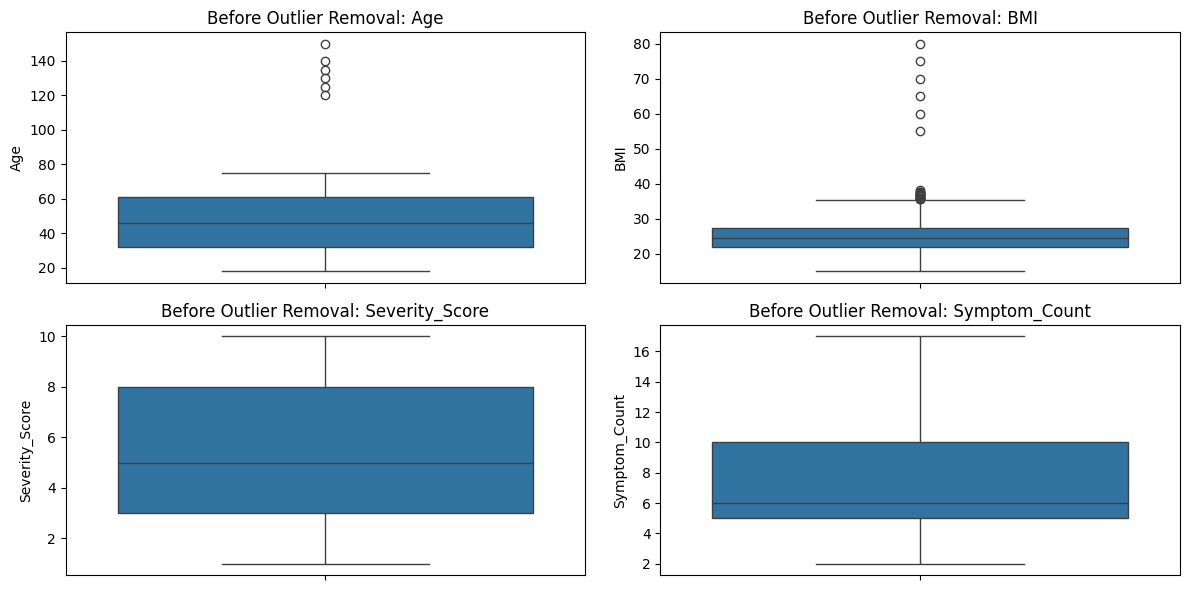

In [ ]:
# BEFORE OUTLIER DETECTION

# Check dataset before outlier removal
print("Dataset shape before outlier removal:", df.shape)

# Select numerical columns
outlier_cols = [
    "Age",
    "BMI",
    "Severity_Score",
    "Symptom_Count"
]

# Display statistical summary
print("\nStatistical Summary:")
print(df[outlier_cols].describe())

# Visualize outliers using boxplots
plt.figure(figsize=(12, 6))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Before Outlier Removal: {col}")

plt.tight_layout()
plt.show()

In [ ]:
# OUTLIER DETECTION AND REMOVAL

# Calculate Q1 and Q3
Q1 = df[outlier_cols].quantile(0.25)
Q3 = df[outlier_cols].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify rows containing outliers
outlier_mask = (
    (df[outlier_cols] < lower_bound) |
    (df[outlier_cols] > upper_bound)
).any(axis=1)

# Count outlier rows
print("Number of outlier rows:", outlier_mask.sum())

# Remove rows containing outliers
df = df.loc[~outlier_mask].reset_index(drop=True)

print("Outlier removal completed!")
print("Dataset shape after removal:", df.shape)

Number of outlier rows: 30
Outlier removal completed!
Dataset shape after removal: (4945, 22)


Dataset shape after outlier removal: (4945, 22)

Statistical Summary After Removal:
               Age          BMI  Severity_Score  Symptom_Count
count  4945.000000  4945.000000     4945.000000    4945.000000
mean     46.387664    24.545217        5.462083       7.435592
std      16.706973     3.899759        2.880900       3.593800
min      18.000000    15.000000        1.000000       2.000000
25%      32.000000    21.900000        3.000000       5.000000
50%      46.000000    24.500000        5.000000       6.000000
75%      61.000000    27.200000        8.000000      10.000000
max      75.000000    35.400000       10.000000      17.000000


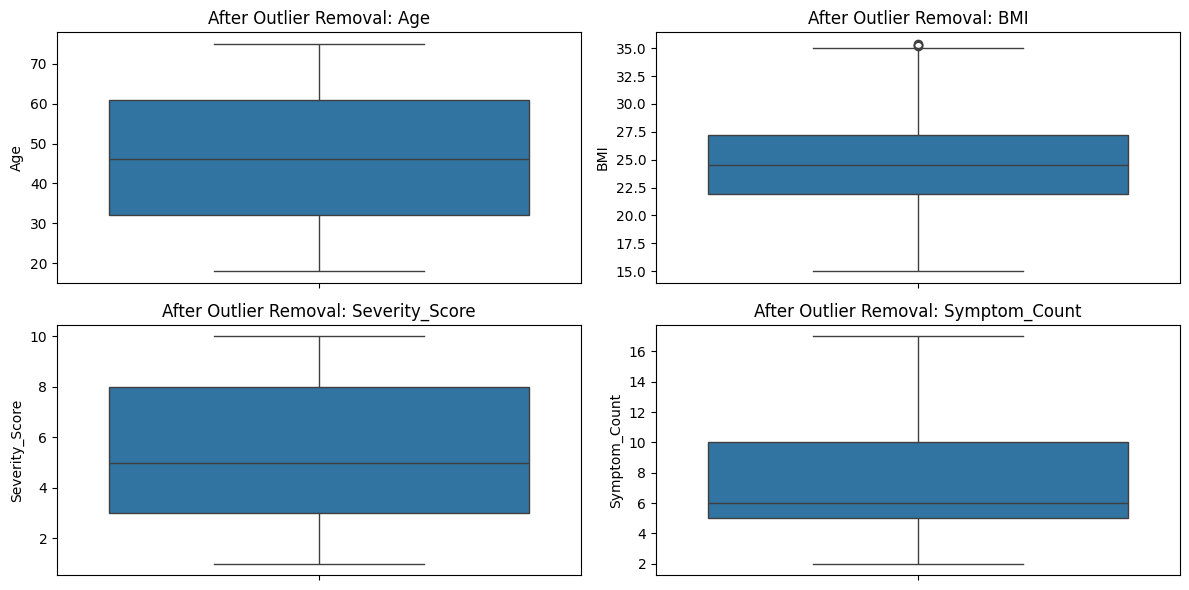

In [ ]:
# AFTER OUTLIER REMOVAL

print("Dataset shape after outlier removal:", df.shape)

print("\nStatistical Summary After Removal:")
print(df[outlier_cols].describe())

# Visualize dataset after removing outliers
plt.figure(figsize=(12, 6))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"After Outlier Removal: {col}")

plt.tight_layout()
plt.show()

In [ ]:
#TRAIN-TEST SPLIT
# ==========================================
# TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Disease"]
)

print("Training Records:",
      len(train_df))

print("Testing Records:",
      len(test_df))

Training Records: 3956
Testing Records: 989


In [ ]:
#SYMPTOM ENCODING
# ==========================================
# SYMPTOM ENCODING
# ==========================================

from sklearn.preprocessing import MultiLabelBinarizer

def create_symptom_lists(data):

    return data[
        symptom_cols
    ].apply(
        lambda row: [
            symptom
            for symptom in row
            if symptom != "unknown"
        ],
        axis=1
    )

train_symptoms = create_symptom_lists(
    train_df
)

test_symptoms = create_symptom_lists(
    test_df
)

mlb = MultiLabelBinarizer()

X_train_symptoms = mlb.fit_transform(
    train_symptoms
)

X_test_symptoms = mlb.transform(
    test_symptoms
)

print("Symptom Encoding completed! ✅")

print(
    "Encoded Symptom Features:",
    X_train_symptoms.shape[1]
)

Symptom Encoding completed! ✅
Encoded Symptom Features: 132


In [ ]:
#CONVERT ENCODED SYMPTOMS TO DATAFRAME
X_train_symptoms = pd.DataFrame(
    X_train_symptoms,
    columns=mlb.classes_,
    index=train_df.index
)

X_test_symptoms = pd.DataFrame(
    X_test_symptoms,
    columns=mlb.classes_,
    index=test_df.index
)

print("Encoded Training Symptoms:")
display(X_train_symptoms.head())

Encoded Training Symptoms:


,abdominal_pain,abnormal_menstruation,acidity,acute_liver_failure,altered_sensorium,anxiety,back_pain,belly_pain,blackheads,bladder_discomfort,...,vomiting,watering_from_eyes,weakness_in_limbs,weakness_of_one_body_side,weight_gain,weight_loss,yellow_crust_ooze,yellow_urine,yellowing_of_eyes,yellowish_skin
1167,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
543,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2668,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
184,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1139,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
#CREATE FINAL FEATURE MATRIX
# ==========================================
# CREATE FEATURE MATRIX
# ==========================================

X_train = pd.concat(
    [
        X_train_symptoms,
        train_df[numeric_cols],
        train_df[["Symptom_Count"]]
    ],
    axis=1
)

X_test = pd.concat(
    [
        X_test_symptoms,
        test_df[numeric_cols],
        test_df[["Symptom_Count"]]
    ],
    axis=1
)

print("Training Feature Matrix:",
      X_train.shape)

print("Testing Feature Matrix:",
      X_test.shape)

Training Feature Matrix: (3956, 136)
Testing Feature Matrix: (989, 136)


In [ ]:
#TARGET ENCODING
# ==========================================
# TARGET ENCODING
# ==========================================

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train = le.fit_transform(
    train_df["Disease"]
)

y_test = le.transform(
    test_df["Disease"]
)

print("Target Encoding completed! ✅")

print(
    "Number of Disease Classes:",
    len(le.classes_)
)

print("\nDisease Mapping:")

for number, disease in enumerate(
    le.classes_
):

    print(
        number,
        "=",
        disease
    )

Target Encoding completed! ✅
Number of Disease Classes: 41

Disease Mapping:
0 = (vertigo) paroymsal  positional vertigo
1 = acne
2 = aids
3 = alcoholic hepatitis
4 = allergy
5 = arthritis
6 = bronchial asthma
7 = cervical spondylosis
8 = chicken pox
9 = chronic cholestasis
10 = common cold
11 = dengue
12 = diabetes
13 = dimorphic hemmorhoids(piles)
14 = drug reaction
15 = fungal infection
16 = gastroenteritis
17 = gerd
18 = heart attack
19 = hepatitis a
20 = hepatitis b
21 = hepatitis c
22 = hepatitis d
23 = hepatitis e
24 = hypertension
25 = hyperthyroidism
26 = hypoglycemia
27 = hypothyroidism
28 = impetigo
29 = jaundice
30 = malaria
31 = migraine
32 = osteoarthristis
33 = paralysis (brain hemorrhage)
34 = peptic ulcer diseae
35 = pneumonia
36 = psoriasis
37 = tuberculosis
38 = typhoid
39 = urinary tract infection
40 = varicose veins


In [ ]:
#FEATURE SELECTION
# ==========================================
# FEATURE SELECTION
# ==========================================

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif
)

k = min(
    50,
    X_train.shape[1]
)

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(
    X_test
)

print("Original Features:",
      X_train.shape[1])

print("Selected Features:",
      X_train_selected.shape[1])

Original Features: 136
Selected Features: 50


In [ ]:
#DISPLAY SELECTED FEATURES
selected_features = X_train.columns[
    selector.get_support()
]

print("Selected Features:")

for feature in selected_features:

    print(feature)

print(
    "\nTotal Selected Features:",
    len(selected_features)
)

Selected Features:
abdominal_pain
abnormal_menstruation
acidity
back_pain
blurred_and_distorted_vision
breathlessness
chest_pain
chills
constipation
continuous_sneezing
cough
dark_urine
depression
diarrhoea
dizziness
excessive_hunger
family_history
fast_heart_rate
fatigue
headache
high_fever
indigestion
irritability
itching
joint_pain
lethargy
loss_of_appetite
loss_of_balance
malaise
mild_fever
mood_swings
muscle_pain
muscle_weakness
nausea
neck_pain
obesity
painful_walking
phlegm
red_spots_over_body
restlessness
skin_rash
stiff_neck
sweating
swelled_lymph_nodes
swelling_joints
vomiting
weight_loss
yellowing_of_eyes
yellowish_skin
Symptom_Count

Total Selected Features: 50


In [ ]:
#FEATURE SCALING
# ==========================================
# FEATURE SCALING
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_selected
)

X_test_scaled = scaler.transform(
    X_test_selected
)

print(
    "Scaled Training Data:",
    X_train_scaled.shape
)

print(
    "Scaled Testing Data:",
    X_test_scaled.shape
)

print(
    "\nFeature Scaling completed! ✅"
)

Scaled Training Data: (3956, 50)
Scaled Testing Data: (989, 50)

Feature Scaling completed! ✅


In [ ]:
# ==========================================
# MULTIPLE CLASSIFIERS
# ==========================================

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import accuracy_score

# ==========================================
# 1. SUPPORT VECTOR MACHINE
# ==========================================

svm_model = SVC(
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_pred = svm_model.predict(
    X_test_scaled
)

svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print("SVM Accuracy:",
      svm_accuracy * 100, "%")


# ==========================================
# 2. K-NEAREST NEIGHBORS
# ==========================================

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_pred = knn_model.predict(
    X_test_scaled
)

knn_accuracy = accuracy_score(
    y_test,
    knn_pred
)

print("KNN Accuracy:",
      knn_accuracy * 100, "%")


# ==========================================
# 3. RANDOM FOREST
# ==========================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train_scaled,
    y_train
)

rf_pred = rf_model.predict(
    X_test_scaled
)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest Accuracy:",
      rf_accuracy * 100, "%")


# ==========================================
# 4. GRADIENT BOOSTING
# ==========================================

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

gb_model.fit(
    X_train_scaled,
    y_train
)

gb_pred = gb_model.predict(
    X_test_scaled
)

gb_accuracy = accuracy_score(
    y_test,
    gb_pred
)

print("Gradient Boosting Accuracy:",
      gb_accuracy * 100, "%")


print("\nAll classifiers trained successfully! ✅")

SVM Accuracy: 98.58442871587462 %
KNN Accuracy: 98.0788675429727 %
Random Forest Accuracy: 98.78665318503539 %
Gradient Boosting Accuracy: 98.78665318503539 %

All classifiers trained successfully! ✅


In [ ]:
# ==========================================
# VOTING ENSEMBLE
# ==========================================

from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(
    estimators=[
        ("svm", svm_model),
        ("knn", knn_model),
        ("rf", rf_model),
        ("gb", gb_model)
    ],
    voting="soft"
)

# Train Voting Ensemble
voting_model.fit(
    X_train_scaled,
    y_train
)

# Make Predictions
voting_pred = voting_model.predict(
    X_test_scaled
)

# Calculate Accuracy
voting_accuracy = accuracy_score(
    y_test,
    voting_pred
)

print("\n======================================")
print("VOTING ENSEMBLE RESULTS")
print("======================================")

print(
    "Voting Ensemble Accuracy:",
    voting_accuracy * 100,
    "%"
)

print("======================================")


VOTING ENSEMBLE RESULTS
Voting Ensemble Accuracy: 98.78665318503539 %



MODEL COMPARISON
SVM: 98.58%
KNN: 98.08%
Random Forest: 98.79%
Gradient Boosting: 98.79%
Voting Ensemble: 98.79%


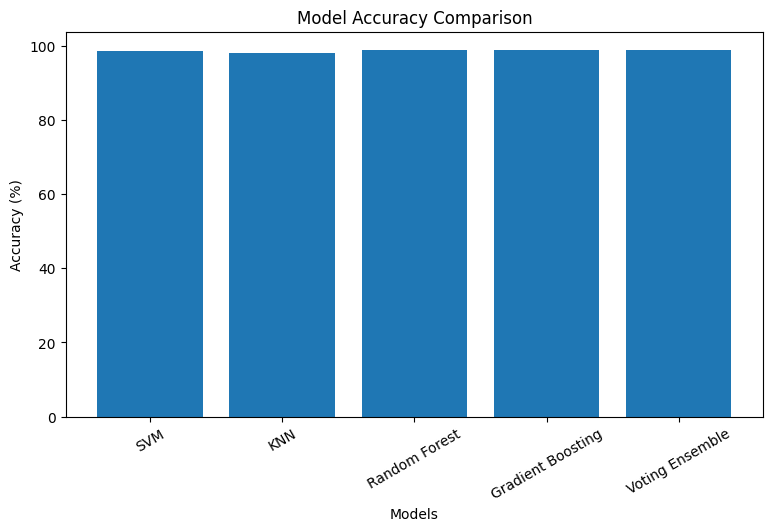

In [ ]:
# ==========================================
# MODEL ACCURACY COMPARISON
# ==========================================

models = [
    "SVM",
    "KNN",
    "Random Forest",
    "Gradient Boosting",
    "Voting Ensemble"
]

accuracies = [
    svm_accuracy,
    knn_accuracy,
    rf_accuracy,
    gb_accuracy,
    voting_accuracy
]

print("\n======================================")
print("MODEL COMPARISON")
print("======================================")

for model, score in zip(models, accuracies):
    print(
        f"{model}: {score * 100:.2f}%"
    )

# Plot Accuracy Comparison

plt.figure(figsize=(9, 5))

plt.bar(
    models,
    [score * 100 for score in accuracies]
)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=30)

plt.show()

In [ ]:
#RANDOM FOREST MODEL

In [ ]:
#Import Random Forest
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [ ]:
#Create Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [ ]:
#Train Random Forest
from sklearn.preprocessing import StandardScaler

# Ensure feature scaling is applied if not already done
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)

rf_model.fit(X_train_scaled, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
#Make Predictions
from sklearn.preprocessing import StandardScaler

# Ensure X_test_scaled is defined
if 'X_test_scaled' not in globals():
    if 'scaler' not in globals():
        scaler = StandardScaler()
        scaler.fit(X_train_selected)
    X_test_scaled = scaler.transform(X_test_selected)

y_pred = rf_model.predict(X_test_scaled)

print("Predictions completed successfully! ✅")
print("First 20 Predictions:")
print(y_pred[:20])

Predictions completed successfully! ✅
First 20 Predictions:
[29 23 14 19  2 34 18  8 35 19 10 22 26  8  4  1 22  0 23 22]


In [ ]:
#Compare Actual and Predicted Values
print("Actual Values:")
print(y_test[:20])

print("\nPredicted Values:")
print(y_pred[:20])

Actual Values:
[29 23 14 19  2 34 18  8 35 19 10 22 26  8  4  1 22  0 23 22]

Predicted Values:
[29 23 14 19  2 34 18  8 35 19 10 22 26  8  4  1 22  0 23 22]


In [ ]:
#Calculate Accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Random Forest Accuracy: 0.9878665318503539
Accuracy Percentage: 98.78665318503539 %


In [ ]:
#Classification Report
from sklearn.metrics import classification_report

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_,
        zero_division=0
    )
)

Classification Report:
                                         precision    recall  f1-score   support

(vertigo) paroymsal  positional vertigo       1.00      1.00      1.00        24
                                   acne       0.92      1.00      0.96        24
                                   aids       0.92      0.92      0.92        24
                    alcoholic hepatitis       1.00      1.00      1.00        24
                                allergy       1.00      0.96      0.98        24
                              arthritis       1.00      1.00      1.00        24
                       bronchial asthma       1.00      1.00      1.00        24
                   cervical spondylosis       1.00      1.00      1.00        25
                            chicken pox       1.00      1.00      1.00        24
                    chronic cholestasis       1.00      1.00      1.00        24
                            common cold       1.00      1.00      1.00        24
    

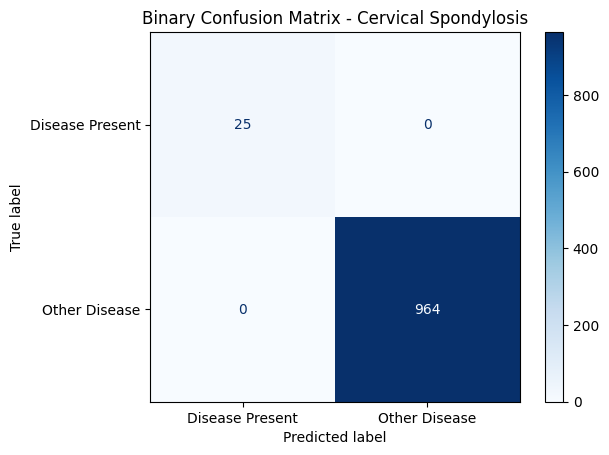

True Positive (TP): 25
True Negative (TN): 964
False Positive (FP): 0
False Negative (FN): 0


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Select one disease
disease_name = "cervical spondylosis"

# Convert disease name into encoded class label
disease_label = le.transform([disease_name])[0]

# Actual and predicted labels: 1 = selected disease, 0 = other diseases
y_actual_binary = (np.array(y_test) == disease_label).astype(int)
y_pred_binary = (np.array(y_pred) == disease_label).astype(int)

# Create 2x2 confusion matrix
cm = confusion_matrix(
    y_actual_binary,
    y_pred_binary,
    labels=[1, 0]
)

# Display the matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Disease Present", "Other Disease"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Binary Confusion Matrix - Cervical Spondylosis")
plt.show()

# Extract TP, FN, FP, TN
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

print("True Positive (TP):", TP)
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)

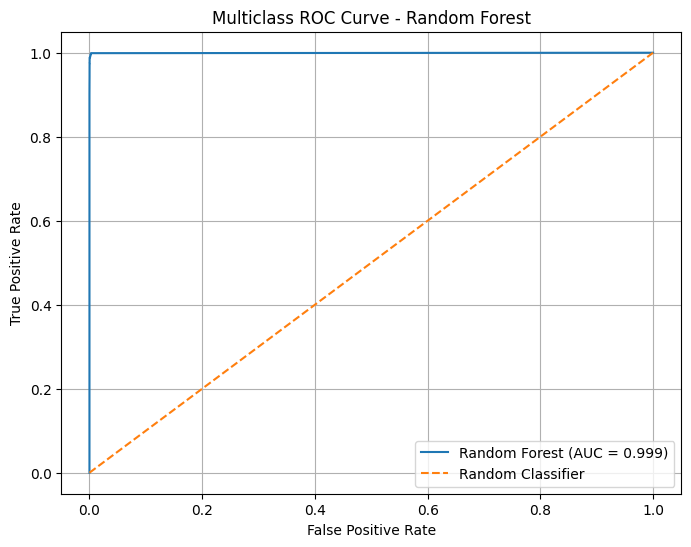

ROC-AUC Score: 0.9994586814923717


In [ ]:
# ==========================================
# ROC CURVE - MULTICLASS
# ==========================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Get probability predictions
y_score = rf_model.predict_proba(X_test_scaled)

# Use only the classes actually used by Random Forest
model_classes = rf_model.classes_

# Convert actual labels into binary format
y_test_bin = label_binarize(
    y_test,
    classes=model_classes
)

# Calculate Micro-average ROC
fpr_micro, tpr_micro, _ = roc_curve(
    y_test_bin.ravel(),
    y_score.ravel()
)

roc_auc_micro = auc(
    fpr_micro,
    tpr_micro
)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_micro,
    tpr_micro,
    label=f"Random Forest (AUC = {roc_auc_micro:.3f})"
)

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curve - Random Forest")

plt.legend()
plt.grid()

plt.show()

print("ROC-AUC Score:", roc_auc_micro)

In [ ]:
# ==========================================
# RANDOM FOREST CLASSIFIER - MODEL SUMMARY
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Precision
precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

# Recall
recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

# F1-Score
f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

# ROC-AUC
roc_auc = roc_auc_micro


# ==========================================
# DISPLAY FINAL RESULTS
# ==========================================

print("==============================================")
print("Random Forest Classifier — Benchmark Model")
print("==============================================")

print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall (Sensitivity): {recall * 100:.2f}%")
print(f"F1-Score: {f1 * 100:.2f}%")
print(f"ROC-AUC Score: {roc_auc:.3f}")

print("==============================================")

Random Forest Classifier — Benchmark Model
Accuracy: 98.79%
Precision: 98.91%
Recall (Sensitivity): 98.79%
F1-Score: 98.80%
ROC-AUC Score: 0.999


In [ ]:
#Feature Importance
import pandas as pd
import matplotlib.pyplot as plt

importance = rf_model.feature_importances_

selected_features = selector.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top Important Features:")
print(feature_importance_df.head(20))

Top Important Features:
              Feature  Importance
49      Symptom_Count    0.103581
20         high_fever    0.048196
22            itching    0.034132
45           vomiting    0.033734
39          skin_rash    0.031652
19           headache    0.029841
13          diarrhoea    0.027023
32             nausea    0.026797
47  yellowing_of_eyes    0.026307
23         joint_pain    0.026007
6          chest_pain    0.025760
18            fatigue    0.024893
0      abdominal_pain    0.024697
8        constipation    0.024637
30        muscle_pain    0.023046
41       stomach_pain    0.022655
25   loss_of_appetite    0.022069
7              chills    0.021299
33          neck_pain    0.020729
48     yellowish_skin    0.019490


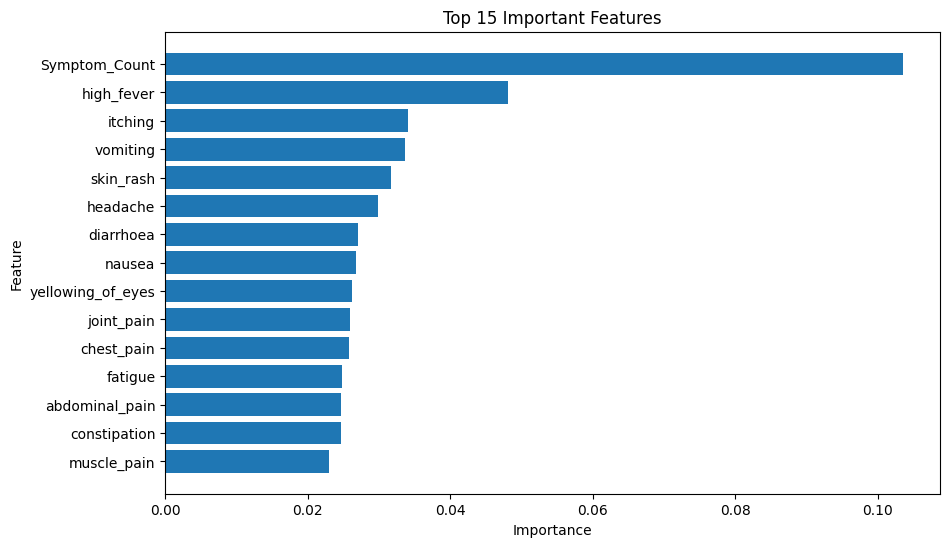

In [ ]:
#Visualize Feature Importance
plt.figure(figsize=(10, 6))

top_features = feature_importance_df.head(15)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
#Save the Random Forest Model
import joblib

joblib.dump(
    rf_model,
    "smart_disease_random_forest.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [ ]:
#Save the Scaler
joblib.dump(
    scaler,
    "smart_disease_scaler.pkl"
)

print("Scaler saved successfully!")

Scaler saved successfully!


In [ ]:
#Save the Label Encoder
joblib.dump(
    le,
    "smart_disease_label_encoder.pkl"
)

print("Label Encoder saved successfully!")

Label Encoder saved successfully!


In [ ]:
#Save Feature Selector
joblib.dump(
    selector,
    "smart_disease_feature_selector.pkl"
)

print("Feature selector saved successfully!")

Feature selector saved successfully!


In [ ]:
#Download Model Files
from google.colab import files

files.download("smart_disease_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Final Model Summary
print("======================================")
print("SMART DISEASE PREDICTION SYSTEM")
print("======================================")

print("Model: Random Forest Classifier")
print("Number of Trees:", rf_model.n_estimators)
print("Accuracy:", accuracy * 100, "%")
print("Number of Disease Classes:", len(le.classes_))

print("======================================")
print("Model training and evaluation completed!")

SMART DISEASE PREDICTION SYSTEM
Model: Random Forest Classifier
Number of Trees: 100
Accuracy: 98.78665318503539 %
Number of Disease Classes: 41
Model training and evaluation completed!


In [ ]:

import pandas as pd
import numpy as np

print("=" * 55)
print("       SMART DISEASE PREDICTION SYSTEM")
print("=" * 55)

print("\nEnter Patient Details")

# ==========================================
# 1. ENTER PATIENT DETAILS
# ==========================================

patient_age = float(input("1. Enter Age: "))
patient_bmi = float(input("2. Enter BMI: "))
patient_severity = float(input("3. Enter Severity Score: "))

# ==========================================
# 2. ENTER SYMPTOMS
# ==========================================

print("\nAvailable symptoms:")
print(", ".join(sorted(str(s) for s in mlb.classes_)))

symptom_input = input(
    "\nEnter patient symptoms separated by commas: "
)

selected_symptoms = [
    symptom.strip().lower()
    for symptom in symptom_input.split(",")
    if symptom.strip()
]

# Check whether symptoms exist in the training encoder
known_symptoms = set(mlb.classes_)

invalid_symptoms = [
    s for s in selected_symptoms
    if s not in known_symptoms
]

if invalid_symptoms:
    print("\nThese symptoms were not found in the dataset:")
    print(", ".join(invalid_symptoms))
    print("Please enter symptoms from the available list.")

else:
    # ==========================================
    # 3. PREPARE PATIENT INPUT
    # ==========================================

    # Use exactly the same feature columns as training
    patient_data = pd.DataFrame(
        np.zeros((1, X_train.shape[1])),
        columns=X_train.columns
    )

    # Add numerical patient details
    patient_data.loc[0, "Age"] = patient_age
    patient_data.loc[0, "BMI"] = patient_bmi
    patient_data.loc[0, "Severity_Score"] = patient_severity

    # Add selected symptoms
    for symptom in selected_symptoms:
        if symptom in patient_data.columns:
            patient_data.loc[0, symptom] = 1

    # Feature engineering
    patient_data.loc[0, "Symptom_Count"] = len(
        selected_symptoms
    )

    # ==========================================
    # 4. FEATURE SELECTION AND SCALING
    # ==========================================

    patient_selected = selector.transform(patient_data)

    patient_scaled = scaler.transform(patient_selected)

    # ==========================================
    # 5. PREDICT DISEASE
    # ==========================================

    prediction = rf_model.predict(patient_scaled)

    predicted_disease = le.inverse_transform(
        prediction
    )[0]

    # ==========================================
    # 6. DISPLAY FINAL RESULT
    # ==========================================

    print("\n" + "=" * 55)
    print("                 PREDICTION RESULT")
    print("=" * 55)

    print("Patient Age:", patient_age)
    print("Patient BMI:", patient_bmi)
    print("Severity Score:", patient_severity)

    print("Selected Symptoms:")
    print(", ".join(selected_symptoms))

    print("\nPredicted Disease:", predicted_disease.title())

    if hasattr(rf_model, "predict_proba"):
        probabilities = rf_model.predict_proba(patient_scaled)[0]
        class_index = list(rf_model.classes_).index(prediction[0])

        print(
            "Model Score for Predicted Class:",
            f"{probabilities[class_index] * 100:.2f}%"
        )

    print("=" * 55)

    print(
        "\nNote: This is an ML-based preliminary prediction, "
        "not a confirmed medical diagnosis."
    )


       SMART DISEASE PREDICTION SYSTEM

Enter Patient Details
